# Chapter 6 — Statistical Machine Learning

**Book:** Practical Statistics for Data Scientists, 2nd Edition  

**Name:** Rainaldi Pakpahan  
**NIM:** 101032300084  
**Class:** TK 47-04  

**Name:** Firdaus Arif Ramadhani  
**NIM:** 101032300131  
**Class:** TK 47-04

Notebook ini mengikuti urutan topik utama Chapter 6 dalam buku karya Peter Bruce, Andrew Bruce, dan Peter Gedeck. Penjelasan diberikan per subtopik secara terperinci, dan contoh Python menggunakan dataset yang tersedia dalam scikit-learn agar bisa dijalankan di Google Colab tanpa unduhan data eksternal. Hasil numerik dapat sedikit berbeda sesuai versi pustaka.

## Persiapan Data Statistical Machine Learning

Chapter 6 membahas algoritma prediktif yang tidak mengharuskan hubungan linear tunggal antara seluruh prediktor dan target. Kita menggunakan dataset breast cancer yang tersedia offline agar setiap algoritma dapat dibandingkan secara konsisten.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
raw=load_breast_cancer(as_frame=True)
X,y=raw.data,raw.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,stratify=y,random_state=42)
print('Training:',X_train.shape,'Testing:',X_test.shape,'Target:',raw.target_names)

Training: (426, 30) Testing: (143, 30) Target: ['malignant' 'benign']


**Interpretasi:** Semua model akan dievaluasi pada pembagian data yang sama. Dengan demikian, perbedaan hasil lebih mudah dikaitkan dengan pendekatan pemodelan dan hyperparameter.

## K-Nearest Neighbors (KNN)

KNN menentukan kelas berdasarkan suara mayoritas dari K titik terdekat. Karena jarak dipengaruhi satuan fitur, standardisasi merupakan langkah penting sebelum menjalankan KNN.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [2]:
from sklearn.neighbors import KNeighborsClassifier
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train,y_train)
knn_pred=knn.predict(X_test)
print('Akurasi KNN:',round(accuracy_score(y_test,knn_pred),3))
print('Prediksi awal:',knn_pred[:12])

Akurasi KNN: 0.979
Prediksi awal: [1 0 1 1 0 0 0 0 0 1 1 1]


**Interpretasi:** Model tidak membentuk rumus global eksplisit, tetapi menggunakan kedekatan data baru dengan data latih. Nilai K yang kecil lebih sensitif pada noise, sementara K yang besar dapat menghaluskan batas keputusan.

## Distance Metrics dan Standardization

Jarak Euclidean mengukur jarak garis lurus, sedangkan Manhattan menjumlahkan selisih absolut. Dengan satuan fitur yang berbeda, pengukuran jarak tanpa standardisasi dapat menyesatkan.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [3]:
from sklearn.metrics import pairwise_distances
v = np.array([[1,2],[4,6],[2,8]])
for metric in ['euclidean','manhattan']:
 print(metric,' — ',np.round(pairwise_distances(v,metric=metric),2))
for metric in ['euclidean','manhattan']:
 model=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5,metric=metric)).fit(X_train,y_train)
 print('Accuracy',metric,round(model.score(X_test,y_test),3))

euclidean  —  [[0.   5.   6.08]
 [5.   0.   2.83]
 [6.08 2.83 0.  ]]
manhattan  —  [[0. 7. 7.]
 [7. 0. 4.]
 [7. 4. 0.]]
Accuracy euclidean 0.979
Accuracy manhattan 0.965


**Interpretasi:** Kedua metrik menghasilkan ukuran kedekatan yang berbeda. Model KNN perlu memilih metrik jarak yang sesuai dengan struktur data, bukan mengasumsikan Euclidean selalu terbaik.

## Memilih Nilai K

Nilai K dapat dipilih menggunakan cross-validation. Evaluasi dilakukan di data latih saja sehingga data uji tetap disimpan untuk evaluasi akhir.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

 K  CV_accuracy
 1        0.937
 3        0.962
 5        0.967
 7        0.965
 9        0.969
11        0.967
15        0.965
21        0.958


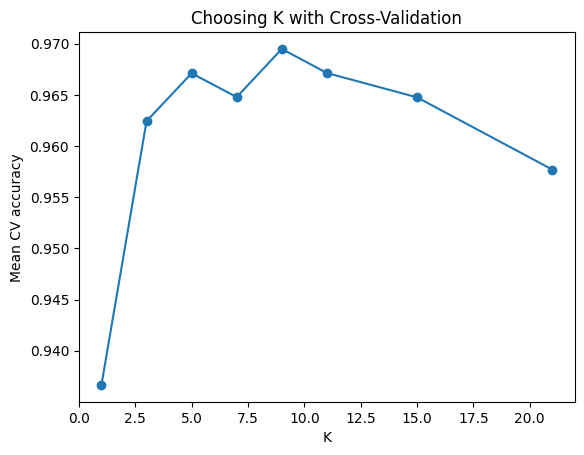

In [4]:
ks=[1,3,5,7,9,11,15,21]
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
results=[]
for k in ks:
 model=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=k))
 results.append(cross_val_score(model,X_train,y_train,cv=cv,scoring='accuracy').mean())
print(pd.DataFrame({'K':ks,'CV_accuracy':np.round(results,3)}).to_string(index=False))
plt.plot(ks,results,marker='o');plt.xlabel('K');plt.ylabel('Mean CV accuracy');plt.title('Choosing K with Cross-Validation');plt.show()

**Interpretasi:** K dengan skor validasi tertinggi menjadi kandidat, tetapi perbedaan sangat kecil tidak selalu bermakna. Cross-validation lebih dapat diandalkan daripada memilih K hanya berdasarkan satu pembagian data.

## KNN sebagai Feature Engine

Selain sebagai model prediksi, jarak ke tetangga terdekat dapat dipakai sebagai fitur baru. Fitur ini merangkum seberapa dekat sebuah observasi dengan pola yang tersedia pada data latih.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [5]:
from sklearn.neighbors import NearestNeighbors
scale=StandardScaler().fit(X_train)
tr=scale.transform(X_train); te=scale.transform(X_test)
nn=NearestNeighbors(n_neighbors=6).fit(tr)
train_dist,_=nn.kneighbors(tr)
test_dist,_=nn.kneighbors(te)
print('Rata-rata jarak ke 5 tetangga (train):',round(train_dist[:,1:].mean(),3))
print('Rata-rata jarak ke 6 tetangga (test):',round(test_dist.mean(),3))

Rata-rata jarak ke 5 tetangga (train): 2.81
Rata-rata jarak ke 6 tetangga (test): 2.793


**Interpretasi:** Data latih mempunyai jarak nol terhadap dirinya sendiri, sehingga tetangga pertama dikeluarkan dari ringkasan train. Untuk observasi uji, seluruh tetangga berasal dari data latih.

## Decision Tree

Pohon keputusan berulang kali membelah data berdasarkan aturan fitur untuk menghasilkan kelompok yang lebih homogen. Keuntungannya adalah aturan prediksi relatif mudah dipahami.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

Train accuracy: 0.974
Test accuracy: 0.944


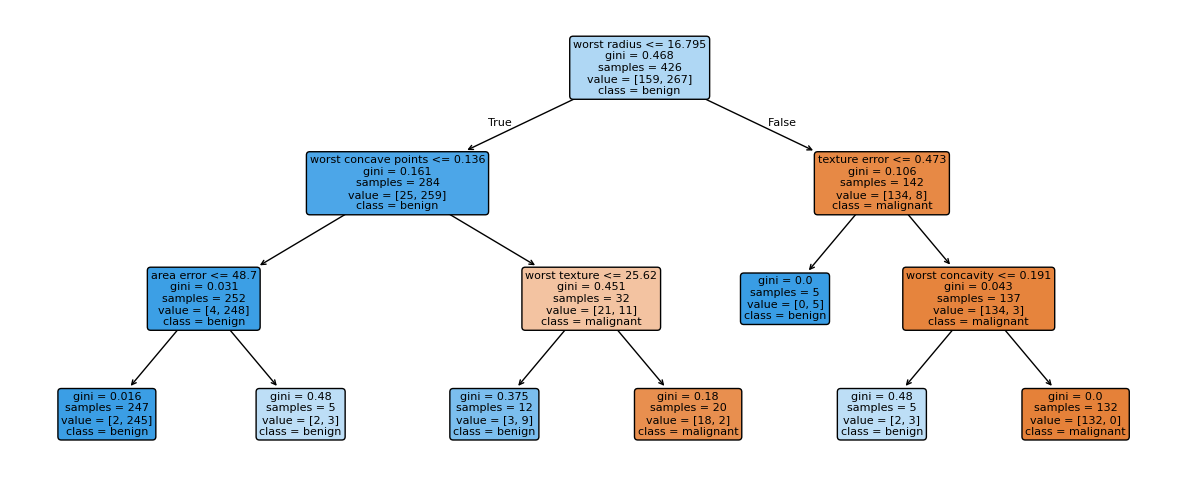

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=42).fit(X_train,y_train)
print('Train accuracy:',round(tree.score(X_train,y_train),3))
print('Test accuracy:',round(tree.score(X_test,y_test),3))
plt.figure(figsize=(15,6))
plot_tree(tree,feature_names=list(X.columns),class_names=list(raw.target_names),filled=True,rounded=True,fontsize=8)
plt.show()

**Interpretasi:** Setiap node menampilkan aturan pembelahan, jumlah sampel, dan distribusi kelas. Membatasi kedalaman dan ukuran daun mengurangi risiko pohon menghafal data latih.

## Impurity dan Pruning

Kriteria Gini dan entropy mengukur ketidakmurnian kelas pada node. Parameter `ccp_alpha` dapat memangkas pohon agar lebih sederhana.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [7]:
for criterion in ['gini','entropy']:
 for alpha in [0.0,0.003,0.01]:
  m=DecisionTreeClassifier(criterion=criterion,ccp_alpha=alpha,random_state=42).fit(X_train,y_train)
  print(f'{criterion:7s} alpha={alpha:.3f} nodes={m.tree_.node_count:3d} test_accuracy={m.score(X_test,y_test):.3f}')

gini    alpha=0.000 nodes= 35 test_accuracy=0.923
gini    alpha=0.003 nodes= 23 test_accuracy=0.937
gini    alpha=0.010 nodes=  9 test_accuracy=0.944
entropy alpha=0.000 nodes= 29 test_accuracy=0.930
entropy alpha=0.003 nodes= 29 test_accuracy=0.930
entropy alpha=0.010 nodes= 29 test_accuracy=0.930


**Interpretasi:** Nilai pruning lebih besar cenderung mengurangi jumlah node, tetapi pemangkasan berlebihan dapat menyebabkan underfitting. Pemilihan parameter sebaiknya menggunakan cross-validation.

## Bagging dan Random Forest

Bagging menggabungkan prediksi banyak model yang dilatih pada sampel bootstrap. Random forest menambahkan pengacakan fitur sehingga pohon lebih beragam.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [8]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
bag=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),n_estimators=70,random_state=42,n_jobs=-1).fit(X_train,y_train)
rf=RandomForestClassifier(n_estimators=120,min_samples_leaf=2,random_state=42,n_jobs=-1).fit(X_train,y_train)
for name,m in [('Bagging',bag),('Random Forest',rf)]:
 print(name,'train=',round(m.score(X_train,y_train),3),'test=',round(m.score(X_test,y_test),3))

Bagging train= 1.0 test= 0.958
Random Forest train= 0.993 test= 0.958


**Interpretasi:** Ensemble mengurangi variasi prediksi dari sebuah pohon tunggal. Selisih skor train-test membantu memeriksa apakah model terlalu menyesuaikan diri dengan data latih.

## Variable Importance

Random forest dapat memberikan ukuran pentingnya fitur berdasarkan rata-rata penurunan impurity. Ukuran ini bermanfaat untuk eksplorasi, tetapi dapat bias pada fitur tertentu dan tidak membuktikan sebab-akibat.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

worst area              0.1650
worst concave points    0.1147
worst perimeter         0.1047
mean concave points     0.1021
worst radius            0.0869
mean perimeter          0.0674
mean radius             0.0628
mean concavity          0.0496
mean area               0.0423
worst concavity         0.0275


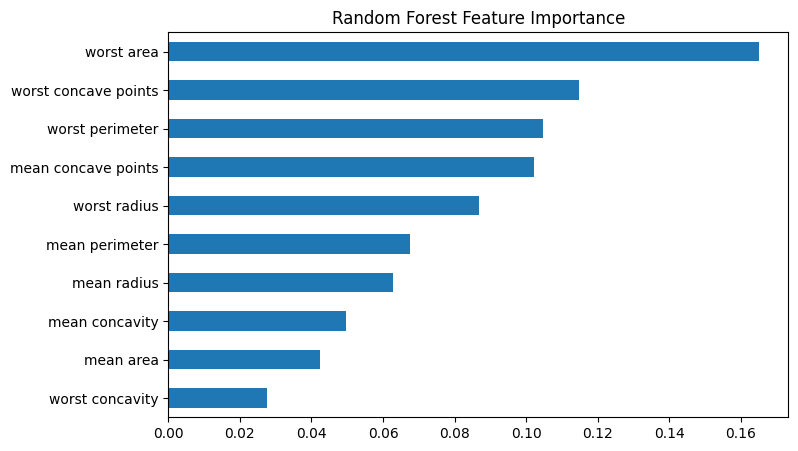

In [9]:
importance=pd.Series(rf.feature_importances_,index=X.columns).sort_values(ascending=False).head(10)
print(importance.round(4).to_string())
importance.sort_values().plot(kind='barh',figsize=(8,5),title='Random Forest Feature Importance')
plt.show()

**Interpretasi:** Fitur dengan nilai tinggi sering dipakai untuk mengurangi ketidakmurnian dalam model tersebut. Untuk analisis yang lebih kuat, pertimbangkan permutation importance di data validasi.

## Boosting

Boosting membangun model secara bertahap sehingga model berikutnya memperbaiki kesalahan sebelumnya. Contoh ini menggunakan GradientBoostingClassifier dari scikit-learn.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [10]:
from sklearn.ensemble import GradientBoostingClassifier
gb=GradientBoostingClassifier(n_estimators=100,learning_rate=0.05,max_depth=2,random_state=42).fit(X_train,y_train)
print('Gradient Boosting train accuracy:',round(gb.score(X_train,y_train),3))
print('Gradient Boosting test accuracy:',round(gb.score(X_test,y_test),3))

Gradient Boosting train accuracy: 0.995
Gradient Boosting test accuracy: 0.944


**Interpretasi:** Kombinasi learning rate, jumlah estimator, dan kedalaman pohon menentukan kekuatan model. Penambahan tahap yang terlalu banyak juga dapat meningkatkan overfitting.

## XGBoost dan Regularisasi

XGBoost merupakan implementasi boosting yang efisien dengan kontrol kompleksitas seperti regularisasi, subsampling, dan ukuran pohon. Paket `xgboost` dapat dipasang di Colab bila belum tersedia.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [11]:
try:
 from xgboost import XGBClassifier
 xgb=XGBClassifier(n_estimators=80,max_depth=3,learning_rate=0.07,subsample=0.85,colsample_bytree=0.85,eval_metric='logloss',random_state=42,n_jobs=2)
 xgb.fit(X_train,y_train)
 print('XGBoost test accuracy:',round(xgb.score(X_test,y_test),3))
except ImportError:
 print('XGBoost belum terpasang. Jalankan: %pip install xgboost')

XGBoost test accuracy: 0.965


**Interpretasi:** XGBoost menggabungkan banyak pohon secara bertahap dan menyediakan pengaturan regularisasi untuk membatasi kompleksitas. Hasil harus dinilai menggunakan data di luar pelatihan.

## Perbandingan Model dengan Cross-Validation

Satu angka akurasi pada data uji bisa dipengaruhi oleh pembagian sampel. Cross-validation pada data latih membantu membandingkan model dengan lebih stabil.

**Catatan pembahasan:** Pada tahap ini, perhatian utama bukan hanya memperoleh skor akhir, melainkan memahami asumsi metode, bentuk data masukan, dan alasan hasil evaluasi bisa berubah ketika model atau parameter diganti. Nilai dari pengujian satu kali diperlakukan sebagai ilustrasi, bukan klaim performa pada semua dataset.

In [12]:
models={'KNN':make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5)),
        'Tree':DecisionTreeClassifier(max_depth=3,random_state=42),
        'Random Forest':RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1),
        'Gradient Boosting':GradientBoostingClassifier(n_estimators=80,random_state=42)}
rows=[]
for name,model in models.items():
 score=cross_val_score(model,X_train,y_train,cv=5,scoring='accuracy')
 rows.append((name,round(score.mean(),3),round(score.std(),3)))
print(pd.DataFrame(rows,columns=['Model','Mean CV Accuracy','CV Std']).to_string(index=False))

            Model  Mean CV Accuracy  CV Std
              KNN             0.962   0.016
             Tree             0.930   0.028
    Random Forest             0.960   0.021
Gradient Boosting             0.953   0.018


**Interpretasi:** Skor rata-rata menunjukkan kinerja selama validasi, sedangkan simpangan baku menunjukkan variasi antarlipatan. Model terbaik tidak hanya dilihat dari akurasi, tetapi juga stabilitas dan kebutuhan interpretasi.

## Pendalaman Subtopik sesuai Struktur Buku

Bagian berikut memperinci konsep-konsep penting yang dibahas di chapter ini. Contoh tambahan menggunakan dataset yang disiapkan pada bagian awal notebook, sehingga setiap pembahasan tetap dapat dijalankan berurutan di Google Colab.

### 1. KNN: Contoh Prediksi Dua Dimensi

KNN bekerja dengan mencari tetangga yang jaraknya paling dekat dengan titik baru. Supaya prinsip ini terlihat, kita gunakan dataset dua fitur. Algoritma tidak membangun koefisien linear seperti regresi; prediksinya bergantung pada posisi titik dalam ruang fitur dan label tetangganya.

Label lima tetangga: [0 0 0 1 0]
Kelas prediksi: 0


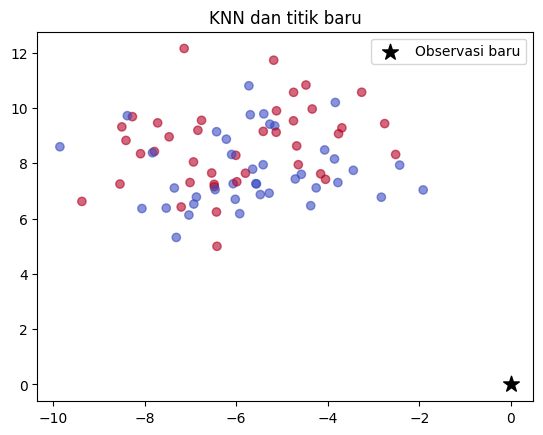

In [13]:
from sklearn.datasets import make_blobs
xb,yb=make_blobs(n_samples=80,centers=2,cluster_std=1.5,random_state=5)
kn2=KNeighborsClassifier(n_neighbors=5).fit(xb,yb)
new=np.array([[0.,0.]])
dist,ix=kn2.kneighbors(new)
print('Label lima tetangga:',yb[ix[0]])
print('Kelas prediksi:',kn2.predict(new)[0])
plt.scatter(xb[:,0],xb[:,1],c=yb,cmap='coolwarm',alpha=.6)
plt.scatter(new[:,0],new[:,1],s=140,marker='*',c='black',label='Observasi baru')
plt.legend();plt.title('KNN dan titik baru');plt.show()

**Interpretasi hasil:** Prediksi dihasilkan dari label tetangga terdekat. KNN dapat mengikuti bentuk sebaran yang rumit, tetapi hasilnya sensitif terhadap posisi titik, pilihan K, metrik jarak, dan normalisasi setiap fitur.

### 2. Minkowski, Euclidean, dan Manhattan Distance

Jarak Euclidean mengukur garis lurus antartitik, sedangkan Manhattan menjumlahkan selisih absolut tiap dimensi. Keduanya adalah kasus khusus dari jarak Minkowski, dengan parameter p=2 dan p=1. Pilihan jarak memengaruhi siapa yang dianggap sebagai tetangga terdekat, terutama ketika fitur memiliki struktur atau skala berbeda.

In [14]:
from scipy.spatial.distance import minkowski, cityblock, euclidean
a=np.array([1.,2.,3.]);b=np.array([4.,4.,8.])
print('Euclidean:',round(euclidean(a,b),3))
print('Manhattan:',round(cityblock(a,b),3))
for p in [1,2,3]:print(f'Minkowski p={p}:',round(minkowski(a,b,p),3))

Euclidean: 6.164
Manhattan: 10.0
Minkowski p=1: 10.0
Minkowski p=2: 6.164
Minkowski p=3: 5.429


**Interpretasi hasil:** Metrik memberikan angka yang berbeda untuk pasangan titik yang sama. Nilai jarak hanya bermakna relatif terhadap definisi metrik dan satuan fitur. Tidak ada alasan untuk membandingkan besar angka Euclidean dan Manhattan sebagai indikator kualitas model.

### 3. One-Hot Encoding untuk Fitur Kategorikal

KNN mengharuskan input numerik agar jarak dapat dihitung. Label kategori yang dikodekan sebagai 0, 1, 2 tanpa alasan ordinal dapat menimbulkan jarak semu. One-hot encoding mengubah kategori menjadi kolom indikator sehingga tidak menambahkan urutan buatan antarkategori. Teknik ini tetap memerlukan pertimbangan karena jumlah kategori yang banyak memperluas dimensi data.

In [15]:
from sklearn.preprocessing import OneHotEncoder
cats=pd.DataFrame({'type':['urban','rural','suburban','urban']})
enc=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
arr=enc.fit_transform(cats)
print(pd.DataFrame(arr,columns=enc.get_feature_names_out()).to_string(index=False))

 type_rural  type_suburban  type_urban
        0.0            0.0         1.0
        1.0            0.0         0.0
        0.0            1.0         0.0
        0.0            0.0         1.0


**Interpretasi hasil:** Setiap kolom menandai kehadiran satu kategori. Encoding seperti ini lebih tepat daripada menetapkan jarak ordinal yang tidak bermakna, tetapi metrik jarak tetap perlu disesuaikan jika satu set data memuat campuran variabel numerik dan kategorikal.

### 4. Standardization dan Dampaknya pada Tetangga

Jika satu fitur berkisar hingga ribuan sedangkan fitur lain hanya berkisar nol sampai satu, fitur pertama akan mendominasi jarak Euclidean. StandardScaler memusatkan fitur dan membagi simpangan bakunya. Perhitungan skala dilakukan pada data latih dan dipakai ulang pada data uji, bukan dihitung ulang secara terpisah.

In [16]:
demo=np.array([[1.,1000.],[2.,1500.],[3.,2200.],[4.,3000.]])
sc=StandardScaler().fit(demo)
print('Sebelum:',demo)
print('Sesudah:',np.round(sc.transform(demo),2))

Sebelum: [[1.0e+00 1.0e+03]
 [2.0e+00 1.5e+03]
 [3.0e+00 2.2e+03]
 [4.0e+00 3.0e+03]]
Sesudah: [[-1.34 -1.23]
 [-0.45 -0.56]
 [ 0.45  0.37]
 [ 1.34  1.43]]


**Interpretasi hasil:** Setelah standardisasi, kedua fitur berada pada skala simpangan baku yang sebanding. Prosedur ini membantu agar jarak tidak terutama ditentukan oleh satuan pengukuran. Namun, standardisasi tidak menjamin bahwa seluruh fitur punya relevansi prediksi yang sama.

### 5. KNN dengan Pembobotan Jarak

Pada pemungutan suara KNN biasa, setiap tetangga punya bobot sama. Dengan `weights="distance"`, tetangga yang lebih dekat memberi pengaruh lebih besar. Pendekatan ini bermanfaat jika kedekatan fisik dalam ruang fitur mencerminkan kemiripan informasi, tetapi bisa lebih sensitif terhadap noise dekat observasi baru.

In [17]:
for weights in ['uniform','distance']:
 model=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=7,weights=weights))
 model.fit(X_train,y_train)
 print(weights,'test accuracy:',round(model.score(X_test,y_test),3))

uniform test accuracy: 0.979
distance test accuracy: 0.979


**Interpretasi hasil:** Perbedaan akurasi antar pembobotan menunjukkan bahwa pilihan aturan suara ikut memengaruhi kinerja. Hasil pada satu pembagian data belum cukup untuk memilih konfigurasi final; perlu validasi silang atau evaluasi terpisah.

### 6. Curse of Dimensionality

Ketika dimensi fitur meningkat, selisih jarak tetangga dekat dan jauh dapat menjadi makin kecil secara relatif. Fenomena ini membuat definisi “dekat” kurang informatif pada beberapa masalah berdimensi tinggi. Eksperimen sintetis berikut membandingkan rasio jarak minimum dan maksimum dari satu titik terhadap banyak titik acak.

In [18]:
rng_hd=np.random.default_rng(13)
for d in [2,10,50,100]:
 cloud=rng_hd.uniform(size=(350,d))
 q=rng_hd.uniform(size=d)
 distances=np.linalg.norm(cloud-q,axis=1)
 print('Dimensi:',d,'rasio min/max:',round(distances.min()/distances.max(),3))

Dimensi: 2 rasio min/max: 0.025
Dimensi: 10 rasio min/max: 0.305
Dimensi: 50 rasio min/max: 0.657
Dimensi: 100 rasio min/max: 0.731


**Interpretasi hasil:** Rasio jarak minimum terhadap maksimum cenderung meningkat pada dimensi tinggi dalam contoh acak ini. Ini memberi gambaran mengapa KNN perlu pemilihan fitur, pembobotan jarak, atau reduksi dimensi ketika jumlah prediktor besar.

### 7. Decision Tree: Aturan Pemisahan

Pohon keputusan membuat aturan bercabang untuk memisahkan observasi berdasarkan nilai prediktor. Pada setiap node, algoritma mencari pemisahan yang meningkatkan homogenitas kelas. Hasilnya relatif mudah dijelaskan, terutama ketika kedalaman pohon dibatasi. Namun, batas keputusan pohon dapat berubah bila data latih sedikit berubah.

In [19]:
from sklearn.tree import DecisionTreeClassifier,export_text
tree_small=DecisionTreeClassifier(max_depth=2,random_state=42).fit(X_train,y_train)
print(export_text(tree_small,feature_names=list(X_train.columns),max_depth=2))
print('Akurasi test:',round(tree_small.score(X_test,y_test),3))

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- class: 0

Akurasi test: 0.909


**Interpretasi hasil:** Aturan pohon yang tercetak menunjukkan fitur dan threshold yang dipakai untuk memisahkan kelas. Model dangkal lebih mudah dibaca, tetapi aturan yang terlalu sederhana bisa gagal menangkap pola penting. Angka test memberi pemeriksaan awal apakah aturan tersebut cukup memadai.

### 8. Entropy dan Gini Impurity

Gini impurity dan entropy sama-sama mengukur campuran kelas di sebuah node. Nilainya rendah ketika sebagian besar anggota node berasal dari kelas yang sama. Kedua metrik tidak selalu memilih pembelahan yang identik, tetapi keduanya memandu pohon ke kelompok yang lebih homogen.

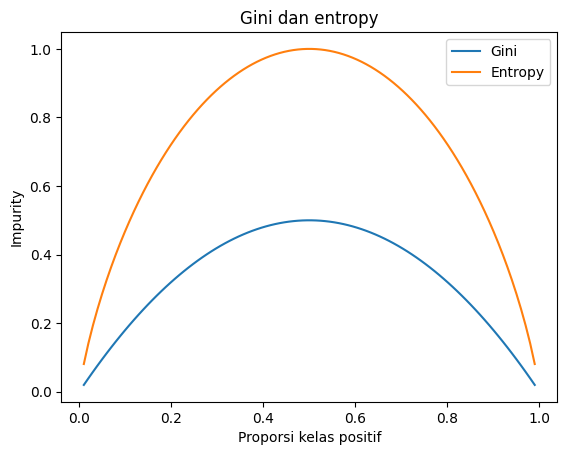

In [20]:
proportions=np.linspace(.01,.99,100)
gini=2*proportions*(1-proportions)
entropy=-(proportions*np.log2(proportions)+(1-proportions)*np.log2(1-proportions))
plt.plot(proportions,gini,label='Gini');plt.plot(proportions,entropy,label='Entropy')
plt.xlabel('Proporsi kelas positif');plt.ylabel('Impurity');plt.title('Gini dan entropy');plt.legend();plt.show()

**Interpretasi hasil:** Kedua kurva bernilai rendah pada node hampir murni dan mencapai puncaknya saat komposisi kelas seimbang. Skala Gini dan entropy berbeda sehingga tinggi kurva tidak dapat dipakai untuk menyimpulkan satu metode selalu lebih unggul.

### 9. Overfitting dan Pembatasan Kedalaman Pohon

Pohon yang sangat dalam dapat menghafal detail spesifik data latih. Ini biasanya memperbesar selisih skor pelatihan dan pengujian. Membatasi kedalaman atau ukuran minimum leaf membantu mengontrol kompleksitas dan menghasilkan aturan yang lebih stabil.

In [21]:
for depth in [2,3,5,None]:
 t=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(X_train,y_train)
 print(f'depth={depth}: train={t.score(X_train,y_train):.3f} | test={t.score(X_test,y_test):.3f}')

depth=2: train=0.958 | test=0.909
depth=3: train=0.977 | test=0.944
depth=5: train=0.995 | test=0.937
depth=None: train=1.000 | test=0.923


**Interpretasi hasil:** Nilai akurasi latih yang sangat tinggi tidak otomatis menunjukkan generalisasi yang baik. Penurunan atau stagnasi nilai uji saat kedalaman ditambah merupakan tanda bahwa model semakin kompleks tanpa manfaat nyata di luar data latih.

### 10. Regression Tree: Prediksi Nilai Kontinu

Pohon keputusan juga dapat memprediksi target numerik. Setiap daun menghasilkan perkiraan nilai kontinu, biasanya berdasarkan rata-rata target pada observasi pelatihan yang masuk ke daun itu. Karena output konstan di tiap region, bentuk prediksinya menyerupai anak tangga dan tidak melakukan ekstrapolasi linear seperti regresi biasa.

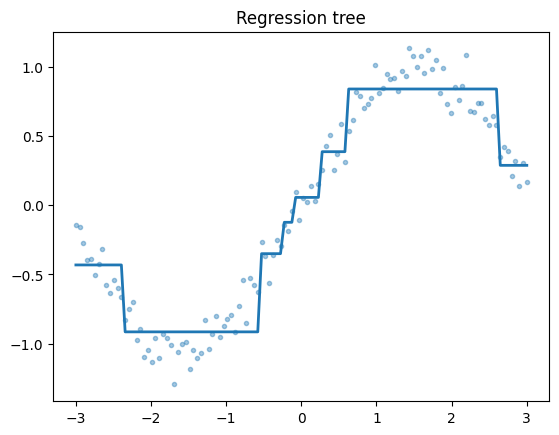

In [22]:
from sklearn.tree import DecisionTreeRegressor
xx=np.linspace(-3,3,120).reshape(-1,1)
yy=np.sin(xx[:,0])+np.random.default_rng(7).normal(0,.12,len(xx))
tr=DecisionTreeRegressor(max_depth=3,random_state=7).fit(xx,yy)
plt.scatter(xx[:,0],yy,s=9,alpha=.4);plt.plot(xx[:,0],tr.predict(xx),linewidth=2)
plt.title('Regression tree');plt.show()

**Interpretasi hasil:** Garis prediksi bertingkat muncul karena observasi dalam satu leaf memperoleh prediksi sama. Model dapat mempelajari hubungan nonlinier, tetapi kedalaman rendah dapat kehilangan detail dan kedalaman berlebih berisiko menyesuaikan noise.

### 11. Bootstrap Sampling dalam Bagging

Bagging membangun banyak model dari sampel bootstrap: dataset pelatihan disampling secara acak dengan pengembalian. Setiap model menerima variasi observasi yang berbeda, lalu prediksinya digabung. Penggabungan tersebut bertujuan mengurangi varians prediksi yang tinggi pada model seperti decision tree.

In [23]:
rng_boot=np.random.default_rng(27)
a=np.arange(12)
for seed in range(3):
 chosen=rng_boot.choice(a,size=len(a),replace=True)
 print('Bootstrap',seed+1,':',chosen,'| unique:',len(np.unique(chosen)))

Bootstrap 1 : [ 0  8  2  3 11  1  7  3  5 11  2  9] | unique: 9
Bootstrap 2 : [ 8  0 10  2  3  3 11 11  3  4  7  2] | unique: 8
Bootstrap 3 : [ 4 10  0 10  1  3  3  4  5  9  7  3] | unique: 8


**Interpretasi hasil:** Dalam satu bootstrap, sebagian observasi muncul beberapa kali dan sebagian tidak muncul sama sekali. Perbedaan sampel ini membuat model dasar tidak identik, sehingga penggabungan hasilnya dapat lebih stabil daripada satu pohon.

### 12. Out-of-Bag Evaluation pada Random Forest

Karena setiap pohon menggunakan bootstrap, sejumlah observasi tidak terambil untuk melatih pohon tersebut. Observasi yang tertinggal ini disebut out-of-bag (OOB) dan dapat digunakan untuk memperkirakan kemampuan generalisasi tanpa membuat set validasi baru. OOB bukan pengganti universal untuk test set independen, tetapi berguna sebagai diagnostik.

In [24]:
from sklearn.ensemble import RandomForestClassifier
rf_oob=RandomForestClassifier(n_estimators=160,oob_score=True,random_state=42,n_jobs=-1)
rf_oob.fit(X_train,y_train)
print('OOB score:',round(rf_oob.oob_score_,3))
print('Test score:',round(rf_oob.score(X_test,y_test),3))

OOB score: 0.962
Test score: 0.958


**Interpretasi hasil:** Kesamaan kasar antara skor OOB dan test mendukung bahwa perkiraan validasi tidak terlalu jauh dari performa di data baru. Perbedaan tetap wajar karena metode sampling dan ukuran data yang digunakan berbeda.

### 13. Permutation Importance vs Impurity Importance

Random forest menyediakan pentingnya fitur berbasis penurunan impurity, tetapi ukuran tersebut memiliki bias tertentu dan tidak langsung menjelaskan manfaat prediktif pada data yang belum dilihat. Permutation importance mengacak satu fitur pada data evaluasi dan mengukur penurunan performa. Pendekatan ini lebih dekat ke pertanyaan tentang kegunaan fitur bagi prediksi model terlatih.

In [25]:
from sklearn.inspection import permutation_importance
pi=permutation_importance(rf_oob,X_test,y_test,n_repeats=3,random_state=42,n_jobs=-1)
ranking=np.argsort(pi.importances_mean)[::-1][:7]
print(pd.DataFrame({'feature':X.columns[ranking],'permutation_drop':pi.importances_mean[ranking]}).round(4).to_string(index=False))

                feature  permutation_drop
          worst texture            0.0047
   worst concave points            0.0023
             worst area            0.0023
        worst concavity            0.0000
         worst symmetry            0.0000
worst fractal dimension            0.0000
       worst smoothness            0.0000


**Interpretasi hasil:** Fitur dengan penurunan skor terbesar memberi kontribusi prediktif paling jelas menurut tes pengacakan ini. Fitur yang saling berkorelasi dapat saling menggantikan sehingga masing-masing terlihat kurang penting, meskipun secara bersama-sama bermanfaat.

### 14. AdaBoost dan Sequential Learning

Berbeda dari bagging yang melatih banyak model relatif independen, boosting menyusun model secara berurutan agar model berikutnya berfokus pada kesalahan tahap sebelumnya. AdaBoost meningkatkan bobot observasi yang sulit diklasifikasi, sementara varian gradient boosting bekerja dengan memperbaiki kesalahan melalui fungsi kerugian.

In [26]:
from sklearn.ensemble import AdaBoostClassifier
ada=AdaBoostClassifier(n_estimators=80,learning_rate=.5,random_state=42).fit(X_train,y_train)
print('AdaBoost train:',round(ada.score(X_train,y_train),3))
print('AdaBoost test:',round(ada.score(X_test,y_test),3))

AdaBoost train: 1.0
AdaBoost test: 0.965


**Interpretasi hasil:** Hasil AdaBoost dapat dibandingkan dengan random forest pada data uji yang sama. Skor yang lebih tinggi belum otomatis membuktikan model selalu lebih bagus; kompleksitas, kestabilan, dan biaya komputasi juga penting.

### 15. Gradient Boosting: Learning Rate dan Banyaknya Tree

Gradient boosting membangun model baru berdasarkan arah pengurangan loss dari ensemble sebelumnya. Learning rate mengatur seberapa besar kontribusi setiap pohon tambahan. Learning rate kecil sering perlu lebih banyak pohon, sedangkan learning rate tinggi dapat menimbulkan penyesuaian terlalu agresif pada data latih.

In [27]:
from sklearn.ensemble import GradientBoostingClassifier
for lr,n_est in [(0.05,70),(0.1,70),(0.1,140)]:
 gb=GradientBoostingClassifier(learning_rate=lr,n_estimators=n_est,max_depth=2,random_state=42).fit(X_train,y_train)
 print(f'lr={lr} trees={n_est}: train={gb.score(X_train,y_train):.3f} test={gb.score(X_test,y_test):.3f}')

lr=0.05 trees=70: train=0.993 test=0.951


lr=0.1 trees=70: train=1.000 test=0.944


lr=0.1 trees=140: train=1.000 test=0.951


**Interpretasi hasil:** Variasi learning rate dan jumlah estimator mengubah kompromi bias dan varians. Skor terbaik pada satu test set sebaiknya tidak digunakan langsung untuk tuning; pilihan parameter ideal ditentukan melalui cross-validation pada data pelatihan.

### 16. Hyperparameter Tuning dengan Grid Search

Parameter model seperti jumlah tetangga, kedalaman pohon, dan batas minimal sampel di leaf tidak dipelajari otomatis melalui proses fitting biasa. Grid search menguji kombinasi parameter melalui validasi silang dan kemudian memilih pengaturan dengan skor rata-rata terbaik. Semua pilihan model di sini menggunakan hanya data pelatihan.

In [28]:
from sklearn.model_selection import GridSearchCV
param={'max_depth':[2,3,4,5],'min_samples_leaf':[1,3,8]}
grid_tree=GridSearchCV(DecisionTreeClassifier(random_state=42),param,cv=3,scoring='balanced_accuracy',n_jobs=-1)
grid_tree.fit(X_train,y_train)
print('Best parameters:',grid_tree.best_params_)
print('Best CV balanced accuracy:',round(grid_tree.best_score_,3))
print('Test accuracy:',round(grid_tree.score(X_test,y_test),3))

Best parameters: {'max_depth': 5, 'min_samples_leaf': 8}
Best CV balanced accuracy: 0.922
Test accuracy: 0.946


**Interpretasi hasil:** Validasi silang digunakan untuk membandingkan parameter tanpa mengambil keputusan berdasarkan set uji. Setelah konfigurasi terbaik ditemukan, evaluasi akhir pada data uji memberi gambaran performa pada observasi yang belum dipakai untuk pemilihan parameter.